# 10 · From a speed table to tensors

**Objective.** Turn METR-LA (34,272 five-minute steps × 207 sensors) into the batches every deep-learning model in this phase trains on, and prove that the batches are correct before any model sees them.

**Concept.** A neural network does not read a table of features the way XGBoost does. It reads *tensors*: blocks of numbers with named axes. For traffic forecasting one training example is

* **input** `x`: the last 60 minutes (12 steps) at all 207 sensors, 6 numbers per sensor and step → `[12, 207, 6]`
* **target** `y`: the next 60 minutes at all 207 sensors → `[12, 207]`
* **mask** `valid`: 1 where the target was actually observed, 0 where the sensor was down → `[12, 207]`

Stacking `B` examples adds a batch axis in front. Every model in notebooks 11–13 takes exactly this batch, so differences between models come from the models, not from the data.

| What you'll learn here | Why it matters |
|---|---|
| tensor shapes `[B, L, N, F]` | every shape bug in DL starts with a misunderstood axis |
| residual targets and the persistence anchor | models learn *the change*, not the absolute speed |
| masking instead of zero-filling | a sensor outage must not look like a traffic jam |
| tests that can fail | the cheapest place to catch a bug is before a 1-hour training run |

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Locate the project root (the folder that contains src/config.py) wherever Jupyter was started.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))

from src import config
config.ensure_dirs()
print(f"project root : .../{ROOT.name}  (absolute paths are not printed)")
print(f"run mode     : {config.RUN_MODE}")

project root : .../T005_MLDL_Project  (absolute paths are not printed)
run mode     : full


In [2]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from src import preprocessing as pp, graph_utils as gu, visualization as viz
from deep_learning.dl.data import WindowData, FEATURES

viz.apply_style()
ctx = pp.load_context()                       # cleaned data + split + scaler written by prepare_data / notebooks 02-03
data = WindowData.from_context(ctx, "cpu")
T, N = ctx.speed.shape
print(f"series: {T:,} steps x {N} sensors | missing cells: {(~ctx.mask).mean():.1%}")
print("forecast origins per split:", {k: len(v) for k, v in ctx.origins.items()})

series: 34,272 steps x 207 sensors | missing cells: 8.1%
forecast origins per split: {'train': 23881, 'val': 3445, 'test': 6901}


## 1 · What one batch looks like

`WindowData.batch(origins)` gathers windows by index. The six input features per sensor and step are listed below. The calendar features are the same for every sensor, so they are broadcast across the sensor axis.

In [3]:
b = data.batch(data.origins["train"][:64])
shape_table = pd.DataFrame(
    [(k, tuple(v.shape), str(v.dtype).replace("torch.", "")) for k, v in b.items()],
    columns=["tensor", "shape", "dtype"]).set_index("tensor")
shape_table["meaning"] = [
    "B=64 windows, L=12 input steps, N=207 sensors, F=6 features",
    "last observed speed in the window (scaled): the persistence forecast",
    "scaled speed at the 12 future steps (0 where missing)",
    "1 = target observed, 0 = sensor down (no loss there)",
    "calendar features of the 12 target times (known in advance)",
]
display(shape_table)
print("input features:", FEATURES)

,shape,dtype,meaning
tensor,,,
x,"(64, 12, 207, 6)",float32,"B=64 windows, L=12 input steps, N=207 sensors,..."
anchor,"(64, 207)",float32,last observed speed in the window (scaled): th...
y,"(64, 12, 207)",float32,scaled speed at the 12 future steps (0 where m...
valid,"(64, 12, 207)",float32,"1 = target observed, 0 = sensor down (no loss ..."
future_time,"(64, 12, 207, 4)",float32,calendar features of the 12 target times (know...


input features: ('speed_z', 'observed', 'tod_sin', 'tod_cos', 'dow_sin', 'dow_cos')


**Why not build all windows once?** Neighbouring windows overlap in 11 of their 12 steps. Materialising them would copy every number 12 times:

In [4]:
n_train = len(ctx.origins["train"])
full = n_train * 12 * N * 6 * 4 / 1e9
series = (3 * T * N + T * 4) * 4 / 1e6
print(f"all training windows as one array : {full:.2f} GB")
print(f"series kept as [T, N] tensors     : {series:.0f} MB  -> a batch is gathered by index on the GPU")

all training windows as one array : 1.42 GB
series kept as [T, N] tensors     : 86 MB  -> a batch is gathered by index on the GPU


## 2 · One window, drawn

The plot shows a single sensor at a single forecast origin from the validation period: the 12 input steps (with gaps where the sensor was down), the **anchor** (the last observed speed, which is what persistence would predict for every future step) and the 12 targets.

Every model predicts `anchor + residual`. If a model learned nothing, the residual would be 0 and the model would *be* persistence. That makes persistence the floor every model has to beat, and it makes training easier: most of the time traffic does not change much in an hour, so the residual is small.

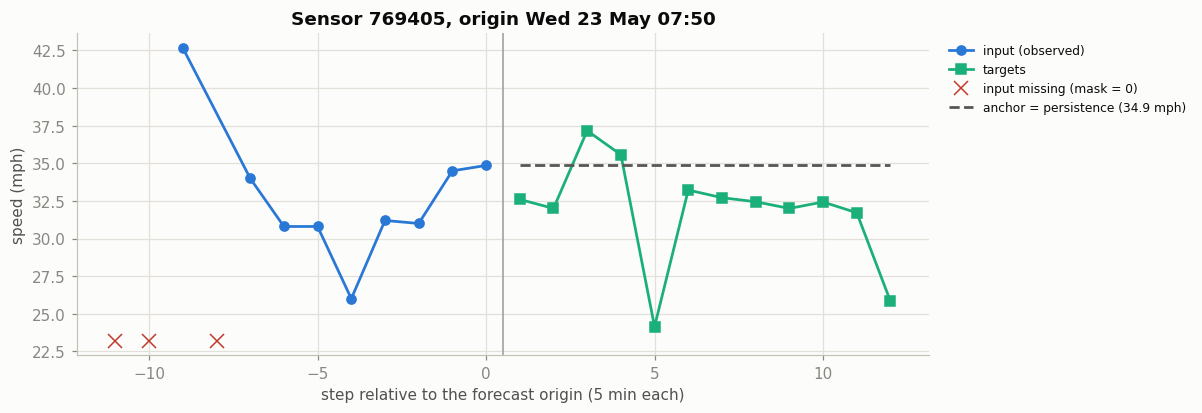

missing input steps are fed as 0 (the training mean, after scaling) AND flagged by the mask channel


In [5]:
val_o = ctx.origins["val"]
vb = data.batch(data.origins["val"])
obs_in, obs_out = vb["x"][..., 1], vb["valid"]                     # [S, L, N], [S, H, N]
change = (data.to_mph(vb["y"]) - data.to_mph(vb["anchor"])[:, None, :])[:, -1]   # 60-min change vs anchor
hour = np.asarray(ctx.timestamps[val_o].hour)[:, None]
good = ((obs_in.sum(1) >= 8) & (obs_in.sum(1) <= 10) & (obs_in[:, -1] == 1)    # a few gaps, last step observed
        & (obs_out.sum(1) == 12)).numpy() & (np.abs(change) > 8) & (hour >= 7) & (hour <= 19)
s_idx, sensor = map(int, np.argwhere(good)[0])
o = int(val_o[s_idx]); one = data.batch(torch.tensor([o]))

inp_mph = data.to_mph(one["x"][0, :, sensor, 0]); inp_obs = one["x"][0, :, sensor, 1].bool().numpy()
tgt_mph = data.to_mph(one["y"][0, :, sensor]); tgt_obs = one["valid"][0, :, sensor].bool().numpy()
anchor = float(data.to_mph(one["anchor"][0, sensor]))

fig, ax = plt.subplots(figsize=(10, 3.8))
steps_in, steps_out = np.arange(-11, 1), np.arange(1, 13)
ax.plot(steps_in[inp_obs], inp_mph[inp_obs], "o-", color="#2a78d6", label="input (observed)")
ax.plot(steps_out[tgt_obs], tgt_mph[tgt_obs], "s-", color="#1baf7a", label="targets")
ax.plot(steps_in[~inp_obs], np.full((~inp_obs).sum(), ax.get_ylim()[0]), "x", color="#c0392b", ms=9, label="input missing (mask = 0)")
ax.hlines(anchor, 1, 12, color="#555", ls="--", label=f"anchor = persistence ({anchor:.1f} mph)")
ax.axvline(0.5, color="#999", lw=1); ax.set_xlabel("step relative to the forecast origin (5 min each)"); ax.set_ylabel("speed (mph)")
ax.set_title(f"Sensor {ctx.sensor_ids[sensor]}, origin {ctx.timestamps[o]:%a %d %b %H:%M}")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); viz.save_figure(fig, "10_one_window"); plt.show()
print("missing input steps are fed as 0 (the training mean, after scaling) AND flagged by the mask channel")

## 3 · Why masking, not zero-filling

In the raw file a missing reading is stored as `0.0 mph`. Taken literally, that is a standstill: the worst traffic jam possible. 2,148 time steps have *all* 207 sensors at exactly 0, which cannot be real traffic.

So the pipeline does two things:
* **inputs**: a missing value becomes the training mean (0 after scaling) and an extra *observed* channel tells the model it is not real;
* **targets**: a missing target gets `valid = 0` and contributes nothing to the loss or to any metric.

In [6]:
rows = []
for split in pp.SPLIT_NAMES:
    a, z = ctx.splits.range(split)
    m = ctx.mask[a:z]
    rows.append({"split": split, "missing cells": f"{(~m).mean():.1%}", "steps with every sensor down": int((~m).all(axis=1).sum())})
display(pd.DataFrame(rows).set_index("split"))

raw_zero_filled = np.nan_to_num(ctx.speed, nan=0.0)
print(f"mean speed if zeros were treated as real : {raw_zero_filled.mean():.1f} mph")
print(f"mean speed of observed readings          : {np.nanmean(ctx.speed):.1f} mph")

,missing cells,steps with every sensor down
split,,
train,7.2%,1301
val,6.9%,181
test,12.0%,666


mean speed if zeros were treated as real : 53.7 mph
mean speed of observed readings          : 58.5 mph


## 4 · Sanity checks that can fail

Three checks on the **real** data (the unit tests in `deep_learning/tests/test_data.py` do the same on synthetic data):

1. the batches are identical to Phase 1's window functions, so DL and XGBoost really see the same inputs;
2. changing every value **after** a forecast origin changes nothing in the inputs (no look-ahead);
3. no training window touches a validation or test row.

In [7]:
rng = np.random.default_rng(0)
o = np.sort(rng.choice(ctx.origins["test"], 32, replace=False))
b = data.batch(torch.as_tensor(o))
x_ref = pp.gather_model_inputs(pp.fill_for_model(ctx.speed, ctx.mask, ctx.scaler), ctx.mask, pp.time_feature_matrix(ctx.timestamps), o, config.INPUT_LEN)
assert np.allclose(b["x"].numpy(), x_ref, atol=1e-6)
print("1. DL batches == Phase 1 window inputs for 32 random test origins")

cut = int(o[0])
wrecked = ctx.speed.copy(); wrecked[cut + 1:] = 99.0
alt = WindowData.from_arrays(wrecked, ctx.mask, ctx.timestamps, ctx.scaler, ctx.origins).batch(torch.tensor([cut]))
assert torch.equal(alt["x"], data.batch(torch.tensor([cut]))["x"]) and torch.equal(alt["anchor"], data.batch(torch.tensor([cut]))["anchor"])
print("2. inputs and anchor unchanged when every row after the origin is overwritten")

tr = ctx.origins["train"]
assert tr.max() + config.MAX_HORIZON < ctx.splits.val[0]
print(f"3. last training target row {tr.max() + config.MAX_HORIZON} < first validation row {ctx.splits.val[0]}")

1. DL batches == Phase 1 window inputs for 32 random test origins


2. inputs and anchor unchanged when every row after the origin is overwritten
3. last training target row 23903 < first validation row 23904


## 5 · The number to beat

Before training anything: how good is the anchor alone? This is persistence on the **validation** split, over all 12 steps, measured exactly the way the training loop measures its models. Test data is not looked at until notebook 14.

In [8]:
err = cnt = 0.0
per_step = np.zeros(12); per_cnt = np.zeros(12)
for bb in data.batches("val", 256):
    e = (bb["anchor"][:, None, :] - bb["y"]).abs() * bb["valid"]
    err += float(e.sum()); cnt += float(bb["valid"].sum())
    per_step += e.sum(dim=(0, 2)).numpy(); per_cnt += bb["valid"].sum(dim=(0, 2)).numpy()
print(f"persistence, validation MAE over all 12 steps: {ctx.scaler.std * err / cnt:.3f} mph")
display(pd.Series(ctx.scaler.std * per_step / per_cnt, index=[f"{5 * (i + 1)} min" for i in range(12)], name="val MAE (mph)").round(3).to_frame().T)

persistence, validation MAE over all 12 steps: 3.872 mph


,5 min,10 min,15 min,20 min,25 min,30 min,35 min,40 min,45 min,50 min,55 min,60 min
val MAE (mph),2.642,2.985,3.235,3.458,3.659,3.844,4.026,4.204,4.368,4.528,4.683,4.839


### Common mistakes this notebook avoids

* **Random train/test split of windows.** Windows overlap by 11 steps, so a random split puts near-copies of test windows in training.
* **Treating 0 mph as data.** The model would learn that sensors randomly drop to a standstill.
* **Scaling with statistics from all data.** The scaler is fitted on training rows only (`scaler.json`, checked by `prepare_data.py`).
* **Materialising every window.** 1.4 GB of duplicated numbers; gathering by index costs nothing.

### Check yourself

1. Why is the loss computed on `anchor + residual` rather than on the residual alone? *(Same thing for the gradient; it keeps every model's output in speed units, so metrics are comparable.)*
2. What would happen to the anchor if a sensor was down for the whole hour? *(It falls back to that sensor's training mean; see `window_anchor`.)*
3. Why may a test window's **inputs** reach into the validation period, but its **targets** may not?